# Cosmic acceleration from DESI BAO without assuming flatness

In this notebook, we relax the assumption of flatness and allow for curvature (Appendix A).

In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid
from scipy.stats import norm, multivariate_normal
from scipy.linalg import block_diag
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
%config InlineBackend.figure_format = 'retina'

In [2]:
# Parameters
m_zmax   = 3            # first 3 redshift bins
N_MOCKS  = int(1e7)
OMEGA_K  = [-1.0, -0.3, -0.1, 0.0, 0.1, 0.3, 1.0]   
OMEGA_K_FIG = [-0.3, 0.3]                           
ZGRID = np.linspace(0.0, 2.5, 20000)

LABELS = {"coasting": "coasting ($q=0$)", "w0wacdm": r"$w_0w_a$CDM", "desi_lcdm": r"$\Lambda$CDM"}
COLORS = {"coasting": "#e0a030", "w0wacdm": "#67b6f3", "desi_lcdm": "dimgray"}
fontsize = 18
cm_rc = {
    "font.size": fontsize, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "font.family": "serif", "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.unicode_minus": False, "axes.formatter.use_mathtext": True,
}
label_real = "DESI DR2 BAO"
color_real = "#22201d"
C_KM_S = 299792.458  # km/s

## Data from DESI DR2

Taken from Table IV of Abdul Karim et al. 2025 (arXiv:2503.14738)

In [3]:
# Tracers & redshifts
TRACERS = ["LRG1", "LRG2", "LRG3+ELG1", "ELG2", "QSO", "Lya"]
Z = np.array([0.510, 0.706, 0.934, 1.321, 1.484, 2.330])

# D_M/r_d
DM = np.array([13.588, 17.351, 21.576, 27.601, 30.512, 38.988]) 
DM_ERR = np.array([0.167, 0.177, 0.152, 0.318, 0.760, 0.531])

# D_H/r_d
DH = np.array([21.863, 19.455, 17.641, 14.176, 12.817, 8.632])        
DH_ERR = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])
R_MH = np.array([-0.459, -0.404, -0.416, -0.434, -0.500, -0.431])

# F_AP = D_M/D_H
FAP = np.array([0.622, 0.892, 1.223, 1.948, 2.386, 4.518])          
FAP_ERR = np.array([0.017, 0.021, 0.019, 0.045, 0.136, 0.097])

# D_V/r_d
DV = np.array([12.720, 16.050, 19.721, 24.252, 26.055, 31.267])
DV_ERR = np.array([0.099, 0.110, 0.091, 0.174, 0.398, 0.256])

# D_V/r_d BGS data
Z_BGS = 0.295
DV_BGS = 7.942
DV_BGS_ERR = 0.075

## Define functions and reference cosmologies

$E(z)=(1+z)e^{Q(z)}$ with $Q(z)=\int_0^z q(z')/(1+z')\,dz'$. 

Reference cosmologies: We take flat ground truths to draw the mocks but analyse them with statistics allowing for curvature.

- **Coasting**, $q(z)\equiv0 \Rightarrow E(z)=1+z$.
- **DESI DR2 flat $\Lambda$CDM**: $\Omega_m=0.2975$ (DESI DR2 BAO-alone fit, arXiv:2503.14738 Eq. 17).
- **DESI+CMB flat $w_0w_a$CDM**: $\Omega_m=0.353$, $w_0=-0.42$, $w_a=-1.75$ with:

$$E_\mathrm{CPL}(z)^2 = \Omega_m(1+z)^3 + (1-\Omega_m)(1+z)^{3(1+w_0+w_a)} \exp(-3 w_a z/(1+z))$$

We only take above values from the papers and analytically fit the overall amplitude $Y$ to the real $D_H/r_d$ BAO data.
$S_F$ is amplitude-free; $S_V$ and $S_{VH}$ are linear in $D/r_d$, so their truth-level values scale with $Y$
(their significance on real data does not depend on it).

In [4]:
def E_coasting(z):
    return 1.0 + np.asarray(z, dtype=float)

def E_cpl(z, om, w0, wa):
    z = np.asarray(z, dtype=float)
    return np.sqrt(om * (1 + z) ** 3 + (1 - om) * (1 + z) ** (3 * (1 + w0 + wa)) * np.exp(-3 * wa * z / (1 + z)))

def theory_curves(E_fn, Y):
    Eg = E_fn(ZGRID)
    dm_grid = (C_KM_S / Y) * cumulative_trapezoid(1.0 / Eg, ZGRID, initial=0.0)
    dh_grid = (C_KM_S / Y) / Eg
    dv_grid = (ZGRID * dm_grid ** 2 * dh_grid) ** (1.0 / 3.0)
    dh = lambda z: np.interp(z, ZGRID, dh_grid)
    dv = lambda z: np.interp(z, ZGRID, dv_grid)
    fap = lambda z: np.interp(z, ZGRID, dm_grid) / dh(z)
    return dh, dv, fap

def fit_amplitude_dh(E_fn):
    x = C_KM_S / E_fn(Z)
    return 1.0 / (np.sum(x * DH / DH_ERR ** 2) / np.sum(x ** 2 / DH_ERR ** 2))

TRUTHS = {
    "coasting": E_coasting,
    "desi_lcdm": lambda z: E_cpl(z, 0.2975, -1.0, 0.0),
    "w0wacdm": lambda z: E_cpl(z, 0.353, -0.42, -1.75),
}

## Curvature-dependent statistics

Without flatness, 
$$D_M(z)=(c/H_0)\,S_k\!\big(\tilde\chi(z)\big)$$
with 
$$\tilde\chi(z)=\int_0^z e^{-Q(z')}/(1+z')\,dz'$$ 
$D_H$ does not depend on curvature. Here $\Omega_k\equiv-kc^2/(a_0H_0)^2$ is purely geometric; no Friedmann equation is used.

Define functions:

- $S_k(x)=\sinh(\sqrt{\Omega_k}\,x)/\sqrt{\Omega_k}$ (open, $\Omega_k>0$) or $\sin(\sqrt{-\Omega_k}\,x)/\sqrt{-\Omega_k}$ (closed, $\Omega_k<0$). 

- $g_k(z) \equiv \left[\frac{z\, S_k^2(\ln(1+z))}{1+z}\right]^{1/3}$ 

- $k_+\equiv\max(\Omega_k,0)$

- $k_-\equiv\min(\Omega_k,0)$

In [5]:
def S_k(x, ok):
    """Comoving transverse distance in units of c/H0 for comoving radial distance x."""
    x = np.asarray(x, dtype=float)
    if ok > 0:
        return np.sinh(np.sqrt(ok) * x) / np.sqrt(ok)
    if ok < 0:
        return np.sin(np.sqrt(-ok) * x) / np.sqrt(-ok)
    return x

def g_k(z, ok):
    """Coasting D_V in units of c/H0: [z S_k(ln(1+z))^2 / (1+z)]^(1/3)."""
    z = np.asarray(z, dtype=float)
    return (z * S_k(np.log1p(z), ok) ** 2 / (1.0 + z)) ** (1.0 / 3.0)

def k_minus(ok): return min(ok, 0.0)   # S_F, S_VH: only closed curvature lowers the bound
def k_plus(ok):  return max(ok, 0.0)   # S_V: only open curvature raises the bound

## Define $S_F$, $S_V$, $S_\mathrm{VH}$ statistics

- $S_F^{(k)}(z)\ \equiv\ (1+z)\,S_{k_-}\big(\ln(1+z)\big)-F_\mathrm{AP}(z)$.

- $S_V^{(k)}(z)\ \equiv\ g_{k_+}(z_\mathrm{ref})\, \frac{D_V(z)}{r_\mathrm{d}}-g_{k_+}(z)\, \frac{D_V(z_\mathrm{ref})}{r_\mathrm{d}}$, $z_{\rm ref}=0.295$ (BGS).

- $S^{(k)}_{VH}(z) = (1+z)\, g_{k_-}(z_\mathrm{ref})\, \frac{D_H(z)}{r_d} - \frac{D_V(z_\mathrm{ref})}{r_d}$ from Sutherland (2012, arXiv:1105.3838).

All three are linear in DESI's quoted $F_{AP}$, $D_V/r_d$ and $D_H/r_d$, so they are exactly Gaussian.

$q \geq 0$ on $[0,z]$ $\implies$ $S(z) \leq 0$.

In [6]:
def S_F(fap, z, ok):
    z = np.asarray(z, dtype=float)
    return (1.0 + z) * S_k(np.log1p(z), k_minus(ok)) - np.asarray(fap, dtype=float)

def S_V(dv, dv_ref, z, ok):
    return g_k(Z_BGS, k_plus(ok)) * np.asarray(dv, dtype=float) - g_k(z, k_plus(ok)) * np.asarray(dv_ref, dtype=float)

def S_VH(dh, dv_ref, z, ok):
    z = np.asarray(z, dtype=float)
    return (1.0 + z) * g_k(Z_BGS, k_minus(ok)) * np.asarray(dh, dtype=float) - np.asarray(dv_ref, dtype=float)

def covariances(ok):
    cov_F = np.diag(FAP_ERR ** 2)
    gV = g_k(Z, k_plus(ok))
    cov_V = np.diag((g_k(Z_BGS, k_plus(ok)) * DV_ERR) ** 2) + DV_BGS_ERR ** 2 * np.outer(gV, gV)
    c = (1.0 + Z) * g_k(Z_BGS, k_minus(ok))
    cov_VH = np.diag((c * DH_ERR) ** 2) + DV_BGS_ERR ** 2 * np.ones((len(Z), len(Z)))
    return {"S_F": cov_F, "S_V": cov_V, "S_VH": cov_VH}

def statistics(fap, dv, dh, dv_ref, ok):
    return {"S_F": S_F(fap, Z, ok), "S_V": S_V(dv, dv_ref, Z, ok), "S_VH": S_VH(dh, dv_ref, Z, ok)}

### Define $Z_\mathrm{max}$ and $Z_\mathrm{avg}$

- $Z_\mathrm{max} = \mathrm{max}_{i \le m} Z_i$ with $Z_i = \left(\frac{S(z_i)}{\sigma_S(z_i)}\right)$
- $Z_\mathrm{avg} = \frac{\bar S_m}{\sigma_{\bar S}}$ with  $\bar S_m = \frac{1}{m}\sum_{i=1}^{m} S(z_i)$
- $Z_\mathrm{max}^\mathrm{corr} = \Phi^{-1}(1-p_\mathrm{obs})$

In [7]:
def Z_scores(S, cov, m=m_zmax):
    """Z_max and Z_avg for one data vector (1D) or many mocks (2D, mocks along axis 0)."""
    sd = np.sqrt(np.diag(cov))[:m]
    sigma_avg = np.sqrt(cov[:m, :m].sum()) / m
    S = np.atleast_2d(S)[:, :m]
    Zmax = (S / sd).max(axis=1)
    Zavg = S.mean(axis=1) / sigma_avg
    return Zmax, Zavg

def Zmax_corrected(zmax, cov, m=m_zmax):
    """Exact look-elsewhere correction: p = 1 - Phi_m(Z_obs,...,Z_obs; R), Z = Phi^-1(1-p)."""
    sd = np.sqrt(np.diag(cov))[:m]
    R = cov[:m, :m] / np.outer(sd, sd)
    p = 1.0 - multivariate_normal.cdf(np.full(m, zmax), mean=np.zeros(m), cov=R, abseps=1e-12, releps=1e-8)
    return float(norm.isf(p)), p

## Generate mocks

Draw DESI's quoted marginals $F_{AP}$, $D_V/r_d$, $D_H/r_d$ (and $D_V/r_d$ at BGS) as independent Gaussians.
Each statistic uses one quoted quantity per tracer, so the within-tracer correlations do not enter.
Compute $S_F$, $S_V$, $S_{VH}$ for truth and for each mock. 

In [8]:
def draw_mocks(E_fn, n_mocks, seed):
    dh_fn, dv_fn, fap_fn = theory_curves(E_fn, fit_amplitude_dh(E_fn))
    rng = np.random.default_rng(seed)
    nt = len(Z)
    true = dict(fap=fap_fn(Z), dv=dv_fn(Z), dh=dh_fn(Z), dv_ref=dv_fn(Z_BGS))
    mock = dict(
        fap=true["fap"][None, :] + rng.normal(0.0, FAP_ERR, size=(n_mocks, nt)),
        dv=true["dv"][None, :] + rng.normal(0.0, DV_ERR, size=(n_mocks, nt)),
        dh=true["dh"][None, :] + rng.normal(0.0, DH_ERR, size=(n_mocks, nt)),
        dv_ref=true["dv_ref"] + rng.normal(0.0, DV_BGS_ERR, size=n_mocks),
    )
    mock["dv_ref"] = mock["dv_ref"][:, None]
    return true, mock

mocks = {t: draw_mocks(E_fn, N_MOCKS, seed=i) for i, (t, E_fn) in enumerate(TRUTHS.items())}

## Fit $H_0\, r_d$ of mocks to real DESI BAO

In [9]:
BAO_VEC = np.concatenate([np.column_stack([DM, DH]).ravel(), [DV_BGS]])
BAO_INV = np.linalg.inv(block_diag(*[[[sm ** 2, r * sm * sh], [r * sm * sh, sh ** 2]] for sm, sh, r in zip(DM_ERR, DH_ERR, R_MH)], [[DV_BGS_ERR ** 2]]))
W0WA = {"desi_lcdm": (-1.0, 0.0), "w0wacdm": (-0.42, -1.75)}

def E_cpl_k(z, om, w0, wa, ok):
    z = np.asarray(z, dtype=float)
    ode = 1.0 - om - ok
    E2 = om * (1 + z) ** 3 + ok * (1 + z) ** 2 + ode * (1 + z) ** (3 * (1 + w0 + wa)) * np.exp(-3 * wa * z / (1 + z))
    return np.sqrt(np.where(E2 > 0, E2, np.nan))

def fit_curved(t, ok):
    """Fit Omega_m to DESI DR2 BAO at fixed (w0, wa, Omega_k); H0 r_d is profiled analytically (BAO scale as 1/(H0 r_d))."""
    w0, wa = W0WA[t]
    zz = np.append(Z, Z_BGS)

    def chi2_and_Y(om):
        E_fn = lambda z: E_cpl_k(z, om, w0, wa, ok)
        dm = C_KM_S * S_k(np.interp(zz, ZGRID, cumulative_trapezoid(1.0 / E_fn(ZGRID), ZGRID, initial=0.0)), ok)
        dh = C_KM_S / E_fn(zz)
        u = np.concatenate([np.column_stack([dm[:-1], dh[:-1]]).ravel(), [(Z_BGS * dm[-1] ** 2 * dh[-1]) ** (1 / 3)]])
        if not np.all(np.isfinite(u)):
            return np.inf, np.nan
        s = (u @ BAO_INV @ BAO_VEC) / (u @ BAO_INV @ u)
        r = BAO_VEC - s * u
        return float(r @ BAO_INV @ r), 1.0 / s

    om = minimize_scalar(lambda om: chi2_and_Y(om)[0], bounds=(0.05, 0.8), method="bounded", options={"xatol": 1e-6}).x
    chi2, Y = chi2_and_Y(om)
    return dict(om=om, Y=Y, chi2=chi2, E=lambda z: E_cpl_k(z, om, w0, wa, ok))

## Analyse data and simulations for each $\Omega_k$

In [10]:
real_data = dict(fap=FAP, dv=DV, dh=DH, dv_ref=DV_BGS)
results = {}   # results[ok][stat] -> dict
for ok in OMEGA_K:
    covs = covariances(ok)
    S_real = statistics(**real_data, ok=ok)
    res = {}
    for stat, cov in covs.items():
        zmax, zavg = Z_scores(S_real[stat], cov)
        zcorr, p = Zmax_corrected(zmax[0], cov)
        r = dict(Zmax_real=zmax[0], Zmax_corr=zcorr, p_max=p, Zavg_real=zavg[0])
        for t, (true, mock) in mocks.items():
            S_true = statistics(**true, ok=ok)[stat]
            S_mock = statistics(**mock, ok=ok)[stat]
            zt_max, zt_avg = Z_scores(S_true, cov)
            zm_max, zm_avg = Z_scores(S_mock, cov)
            r[t] = dict(Zmax_true=zt_max[0], Zmax_mock=zm_max, Zavg_true=zt_avg[0], Zavg_mock=zm_avg)
            if t == "coasting":
                # Monte Carlo check of the look-elsewhere correction: the noise part of the
                # mocks, S_mock - S_true, is a draw from the least-favourable null (S_true = 0).
                null_max, _ = Z_scores(S_mock - S_true, cov)
                p_mc = np.mean(null_max >= zmax[0])
                r["Zmax_corr_MC"] = float(norm.isf(p_mc)) if p_mc > 0 else np.inf
        res[stat] = r
    results[ok] = res

# Plot observables

$\Lambda$CDM                             $w_0w_a$CDM                \
          Omega_m H0 r_d [km/s] chi2 (13 pts)     Omega_m H0 r_d [km/s]   
-0.3       0.3663    10476.2784       95.1922      0.4444     9365.6769   
+0.0       0.2973    10154.9785       10.5386      0.3597     9345.7761   
+0.3       0.2451     9760.2588       49.5116      0.2846     9281.1006   

                    
     chi2 (13 pts)  
-0.3       43.1990  
+0.0        6.5121  
+0.3       46.1315

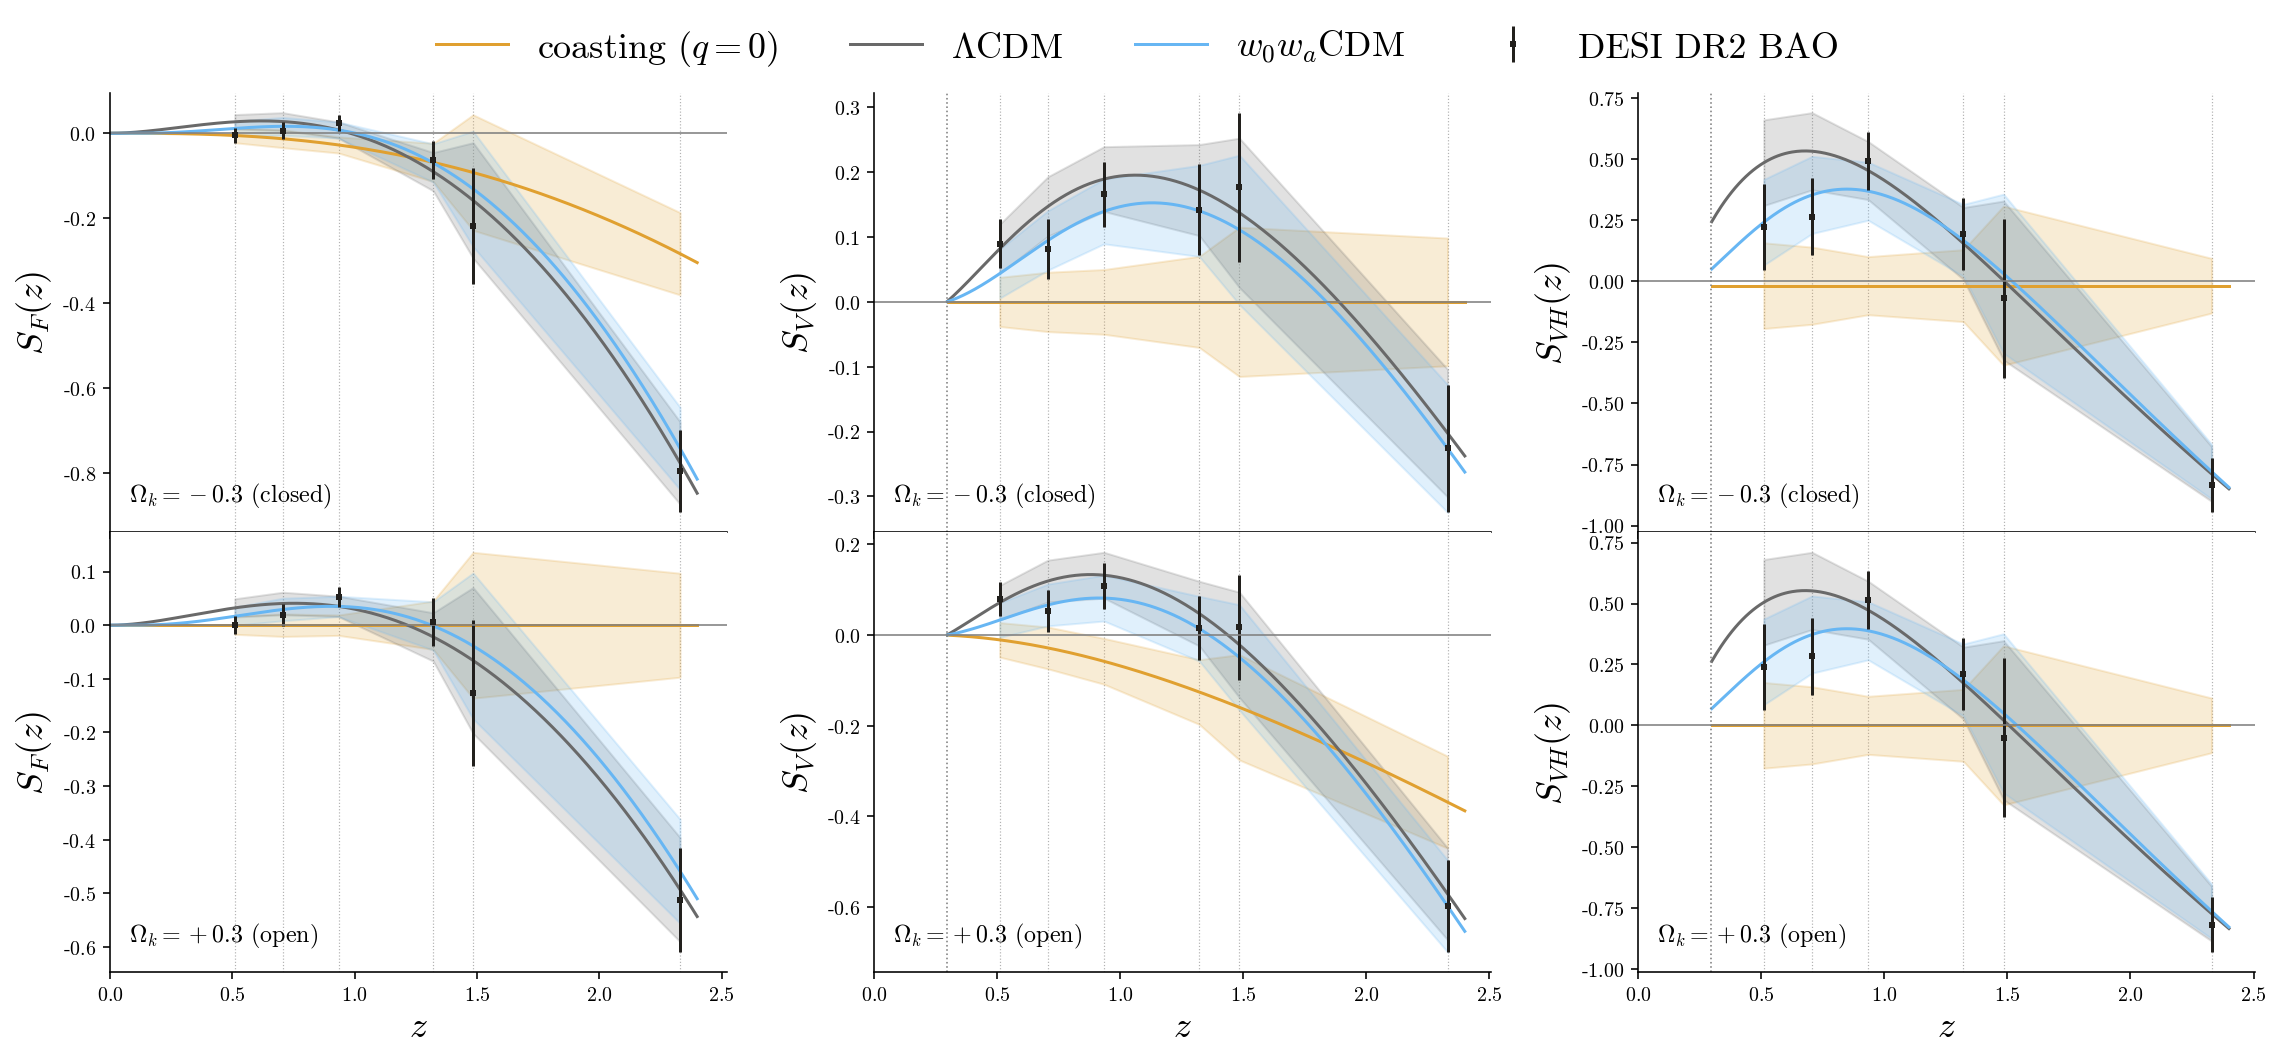

In [11]:
# Curvature statistics: closed (top) and open (bottom); flat-truth models, mock 68% bands, DESI DR2 data
markersize, lw = 2, 1.5
zfine = np.linspace(1e-4, 2.4, 500)
curves = {t: theory_curves(E_fn, fit_amplitude_dh(E_fn)) for t, E_fn in TRUTHS.items()}   # (dh, dv, fap) of the flat truths
stat_ylabel = {"S_F": r"$S_F(z)$", "S_V": r"$S_V(z)$", "S_VH": r"$S_{VH}(z)$"}

# w0wa truths refitted at fixed Omega_k
FITS_K = {ok: {t: fit_curved(t, ok) for t in W0WA} for ok in sorted(set(OMEGA_K_FIG) | {0.0})}
display(pd.DataFrame({(LABELS[t], q): {f"{ok:+.1f}": FITS_K[ok][t][k] for ok in FITS_K}
                      for t in W0WA for q, k in (("Omega_m", "om"), ("H0 r_d [km/s]", "Y"), (f"chi2 ({len(BAO_VEC)} pts)", "chi2"))}).round(4))

def S_model(dh, dv, fap, dv_ref, ok):
    """S_F, S_V, S_VH on zfine from distances evaluated on zfine."""
    return {"S_F": S_F(fap, zfine, ok), "S_V": S_V(dv, dv_ref, zfine, ok), "S_VH": S_VH(dh, dv_ref, zfine, ok)}

with plt.rc_context(cm_rc):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex="col")
    for row, ok in enumerate(sorted(OMEGA_K_FIG)):
        kind_name = "closed" if ok < 0 else "open"
        # Analytic curved coasting (no grid integration) saturates the reference where it is attained, else obeys the null bound
        S_coast = S_model(1 / (1 + zfine), g_k(zfine, ok), (1 + zfine) * S_k(np.log1p(zfine), ok), g_k(Z_BGS, ok), ok)
        for stat, S in S_coast.items():
            S = S if stat == "S_F" else S[zfine >= Z_BGS]
            attained = (ok < 0 and stat != "S_V") or (ok > 0 and stat == "S_V")
            assert np.allclose(S, 0.0, atol=1e-12) if attained else np.all(S <= 1e-12), f"coasting check failed: {stat}, Omega_k = {ok}"
        S_real, covs = statistics(**real_data, ok=ok), covariances(ok)
        S_truth = {t: S_model(dh(zfine), dv(zfine), fap(zfine), dv(Z_BGS), ok) for t, (dh, dv, fap) in curves.items()}
        S_mock = {t: statistics(**mocks[t][1], ok=ok) for t in TRUTHS}
        for col, stat in enumerate(stat_ylabel):
            ax = axes[row, col]
            m = zfine >= (0.0 if stat == "S_F" else Z_BGS)   # no model lines below z_ref for S_V, S_VH
            for t in TRUTHS:
                ax.plot(zfine[m], S_truth[t][stat][m], color=COLORS[t], label=LABELS[t])
                ax.fill_between(Z, *np.percentile(S_mock[t][stat], [15.87, 84.13], axis=0), color=COLORS[t], alpha=0.2)
            ax.errorbar(Z, S_real[stat], np.sqrt(np.diag(covs[stat])), marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
            for z in Z:
                ax.axvline(z, color="grey", lw=0.6, ls=":", alpha=0.6, zorder=0)
            ax.axhline(0, color="grey", lw=0.8)
            if stat != "S_F":
                ax.axvline(Z_BGS, color="grey", lw=0.8, ls=":")
            ax.set_xlim(0)
            ax.set_ylabel(stat_ylabel[stat], fontsize=fontsize)
            ax.text(0.03, 0.05, rf"$\Omega_k = {ok:+.1f}$ ({kind_name})", transform=ax.transAxes, ha="left", va="bottom", fontsize=12)
            ax.spines[["top", "right"]].set_visible(False)
            if row == 0:
                ax.tick_params(labelbottom=False)
            else:
                ax.set_xlabel("$z$", fontsize=fontsize)
    for col in range(3):
        fig.align_ylabels(axes[:, col])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
    fig.subplots_adjust(hspace=0.0)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=len(labels), frameon=False, fontsize=fontsize)
    #plt.savefig("Fig1_Omk_S.pdf", format="PDF", bbox_inches="tight")
    plt.show()

## DESI DR2 significance for different $\Omega_k$

In [12]:
rows = {}
for ok in OMEGA_K:
    row = {}
    for stat in ("S_F", "S_V", "S_VH"):
        r = results[ok][stat]
        row[(stat, "Z_max")] = r["Zmax_real"]
        row[(stat, "Z_max^corr")] = r["Zmax_corr"]
        row[(stat, "Z_max^corr (MC)")] = r["Zmax_corr_MC"]
        row[(stat, "Z_avg")] = r["Zavg_real"]
    rows[ok] = row
tab3 = pd.DataFrame(rows).T
tab3.index.name = "Omega_k"
display(tab3.round(2))

S_F                                    S_V             \
        Z_max Z_max^corr Z_max^corr (MC) Z_avg Z_max Z_max^corr   
Omega_k                                                           
-1.0    -1.01      -2.67           -2.67 -2.38  3.33       3.04   
-0.3     1.32       0.66            0.66  0.80  3.33       3.04   
-0.1     2.29       1.84            1.84  1.72  3.33       3.04   
 0.0     2.77       2.39            2.39  2.19  3.33       3.04   
 0.1     2.77       2.39            2.39  2.19  2.93       2.62   
 0.3     2.77       2.39            2.39  2.19  2.14       1.79   
 1.0     2.77       2.39            2.39  2.19  1.43       1.03   

                               S_VH                                   
        Z_max^corr (MC) Z_avg Z_max Z_max^corr Z_max^corr (MC) Z_avg  
Omega_k                                                               
-1.0               3.04  2.85  3.80       3.52            3.52  2.66  
-0.3               3.04  2.85  4.16       3.90            3.89  3.05  
-0.1               3.04  2.85  4.26       4.01            4.00  3.16  
 0.0               3.04  2.85  4.31       4.06            4.05  3.22  
 0.1               2.62  2.57  4.31       4.06            4.05  3.22  
 0.3               1.79  2.02  4.31       4.06            4.05  3.22  
 1.0               1.03  0.11  4.31       4.06            4.05  3.22

In [13]:
# LaTeX table: Z_max / Z_max^corr / Z_avg per statistic
for ok in OMEGA_K:
    cells = " & ".join(f"${results[ok][s]['Zmax_real']:.2f}$ & ${results[ok][s]['Zmax_corr']:.2f}$ & ${results[ok][s]['Zavg_real']:.2f}$"
                       for s in ("S_F", "S_V", "S_VH"))
    print(f"${ok:+.1f}$ & {cells} \\\\")

$-1.0$ & $-1.01$ & $-2.67$ & $-2.38$ & $3.33$ & $3.04$ & $2.85$ & $3.80$ & $3.52$ & $2.66$ \\
$-0.3$ & $1.32$ & $0.66$ & $0.80$ & $3.33$ & $3.04$ & $2.85$ & $4.16$ & $3.90$ & $3.05$ \\
$-0.1$ & $2.29$ & $1.84$ & $1.72$ & $3.33$ & $3.04$ & $2.85$ & $4.26$ & $4.01$ & $3.16$ \\
$+0.0$ & $2.77$ & $2.39$ & $2.19$ & $3.33$ & $3.04$ & $2.85$ & $4.31$ & $4.06$ & $3.22$ \\
$+0.1$ & $2.77$ & $2.39$ & $2.19$ & $2.93$ & $2.62$ & $2.57$ & $4.31$ & $4.06$ & $3.22$ \\
$+0.3$ & $2.77$ & $2.39$ & $2.19$ & $2.14$ & $1.79$ & $2.02$ & $4.31$ & $4.06$ & $3.22$ \\
$+1.0$ & $2.77$ & $2.39$ & $2.19$ & $1.43$ & $1.03$ & $0.11$ & $4.31$ & $4.06$ & $3.22$ \\


## Simulations for different $\Omega_k$

$Z_{\rm true}$ is the noiseless truth, $\langle Z\rangle$ and ${\rm std}(Z)$ the mean and standard deviation over the simulations. For the coasting truth, $Z_{\rm true}<0$ wherever $\Omega_k$ moves the reference away from flat coasting: the flat coasting universe is not always the least-favourable member of the null.

In [14]:
for ok in OMEGA_K:
    rows = {}
    for stat in ("S_F", "S_V", "S_VH"):
        for t in TRUTHS:
            r = results[ok][stat][t]
            rows[(stat, LABELS[t])] = {
                ("Z_max", "Z_true"): r["Zmax_true"], ("Z_max", "<Z>"): r["Zmax_mock"].mean(), ("Z_max", "std"): r["Zmax_mock"].std(),
                ("Z_avg", "Z_true"): r["Zavg_true"], ("Z_avg", "<Z>"): r["Zavg_mock"].mean(), ("Z_avg", "std"): r["Zavg_mock"].std(),
            }
    print(f"Omega_k = {ok:+.1f}") 
    display(pd.DataFrame(rows).T.round(2))

Omega_k = -1.0


Z_max              Z_avg           
                      Z_true   <Z>   std Z_true   <Z>  std
S_F  coasting ($q=0$)  -1.03 -0.83  0.87  -4.56 -4.56  1.0
     $\Lambda$CDM       0.87  1.08  0.87  -1.30 -1.30  1.0
     $w_0w_a$CDM       -0.05  0.27  0.84  -2.11 -2.11  1.0
S_V  coasting ($q=0$)   0.00  0.49  0.92   0.00  0.00  1.0
     $\Lambda$CDM       3.79  3.89  0.96   3.53  3.53  1.0
     $w_0w_a$CDM        2.79  2.86  0.97   2.35  2.35  1.0
S_VH coasting ($q=0$)  -0.33  0.33  0.82  -0.55 -0.55  1.0
     $\Lambda$CDM       3.46  3.86  0.85   4.18  4.18  1.0
     $w_0w_a$CDM        2.75  2.96  0.89   2.61  2.61  1.0

Omega_k = -0.3


Z_max              Z_avg           
                      Z_true   <Z>   std Z_true   <Z>  std
S_F  coasting ($q=0$)  -0.31  0.18  0.78  -1.39 -1.39  1.0
     $\Lambda$CDM       1.59  2.09  0.79   1.88  1.88  1.0
     $w_0w_a$CDM        0.78  1.48  0.75   1.07  1.07  1.0
S_V  coasting ($q=0$)   0.00  0.49  0.92   0.00  0.00  1.0
     $\Lambda$CDM       3.79  3.89  0.96   3.53  3.53  1.0
     $w_0w_a$CDM        2.79  2.86  0.97   2.35  2.35  1.0
S_VH coasting ($q=0$)  -0.10  0.61  0.82  -0.16 -0.16  1.0
     $\Lambda$CDM       3.82  4.17  0.85   4.57  4.57  1.0
     $w_0w_a$CDM        3.11  3.29  0.90   3.00  3.00  1.0

Omega_k = -0.1


Z_max              Z_avg           
                      Z_true   <Z>   std Z_true   <Z>  std
S_F  coasting ($q=0$)  -0.10  0.60  0.75  -0.46 -0.46  1.0
     $\Lambda$CDM       1.79  2.49  0.75   2.80  2.80  1.0
     $w_0w_a$CDM        1.36  2.01  0.76   1.99  1.99  1.0
S_V  coasting ($q=0$)   0.00  0.49  0.92   0.00  0.00  1.0
     $\Lambda$CDM       3.79  3.89  0.96   3.53  3.53  1.0
     $w_0w_a$CDM        2.79  2.86  0.97   2.35  2.35  1.0
S_VH coasting ($q=0$)  -0.03  0.69  0.82  -0.05 -0.05  1.0
     $\Lambda$CDM       3.92  4.26  0.86   4.69  4.69  1.0
     $w_0w_a$CDM        3.21  3.38  0.90   3.11  3.11  1.0

... (4 outputs left out)

Omega_k = +0.3


Z_max              Z_avg           
                      Z_true   <Z>   std Z_true   <Z>  std
S_F  coasting ($q=0$)   0.00  0.85  0.75   0.00 -0.00  1.0
     $\Lambda$CDM       1.93  2.74  0.75   3.27  3.27  1.0
     $w_0w_a$CDM        1.84  2.33  0.77   2.45  2.45  1.0
S_V  coasting ($q=0$)  -0.27 -0.05  0.94  -0.81 -0.81  1.0
     $\Lambda$CDM       2.61  2.93  0.94   2.70  2.70  1.0
     $w_0w_a$CDM        1.61  1.87  0.94   1.52  1.52  1.0
S_VH coasting ($q=0$)   0.00  0.73  0.82   0.00  0.00  1.0
     $\Lambda$CDM       3.97  4.30  0.86   4.74  4.74  1.0
     $w_0w_a$CDM        3.26  3.43  0.90   3.17  3.17  1.0

Omega_k = +1.0


Z_max              Z_avg           
                      Z_true   <Z>   std Z_true   <Z>  std
S_F  coasting ($q=0$)   0.00  0.85  0.75   0.00 -0.00  1.0
     $\Lambda$CDM       1.93  2.74  0.75   3.27  3.27  1.0
     $w_0w_a$CDM        1.84  2.33  0.77   2.45  2.45  1.0
S_V  coasting ($q=0$)  -0.91 -0.87  0.98  -2.65 -2.65  1.0
     $\Lambda$CDM       1.23  1.54  0.94   0.80  0.80  1.0
     $w_0w_a$CDM        0.23  0.48  0.94  -0.38 -0.38  1.0
S_VH coasting ($q=0$)   0.00  0.73  0.82   0.00  0.00  1.0
     $\Lambda$CDM       3.97  4.30  0.86   4.74  4.74  1.0
     $w_0w_a$CDM        3.26  3.43  0.90   3.17  3.17  1.0

## Distribution of Z-score for closed and an open universe

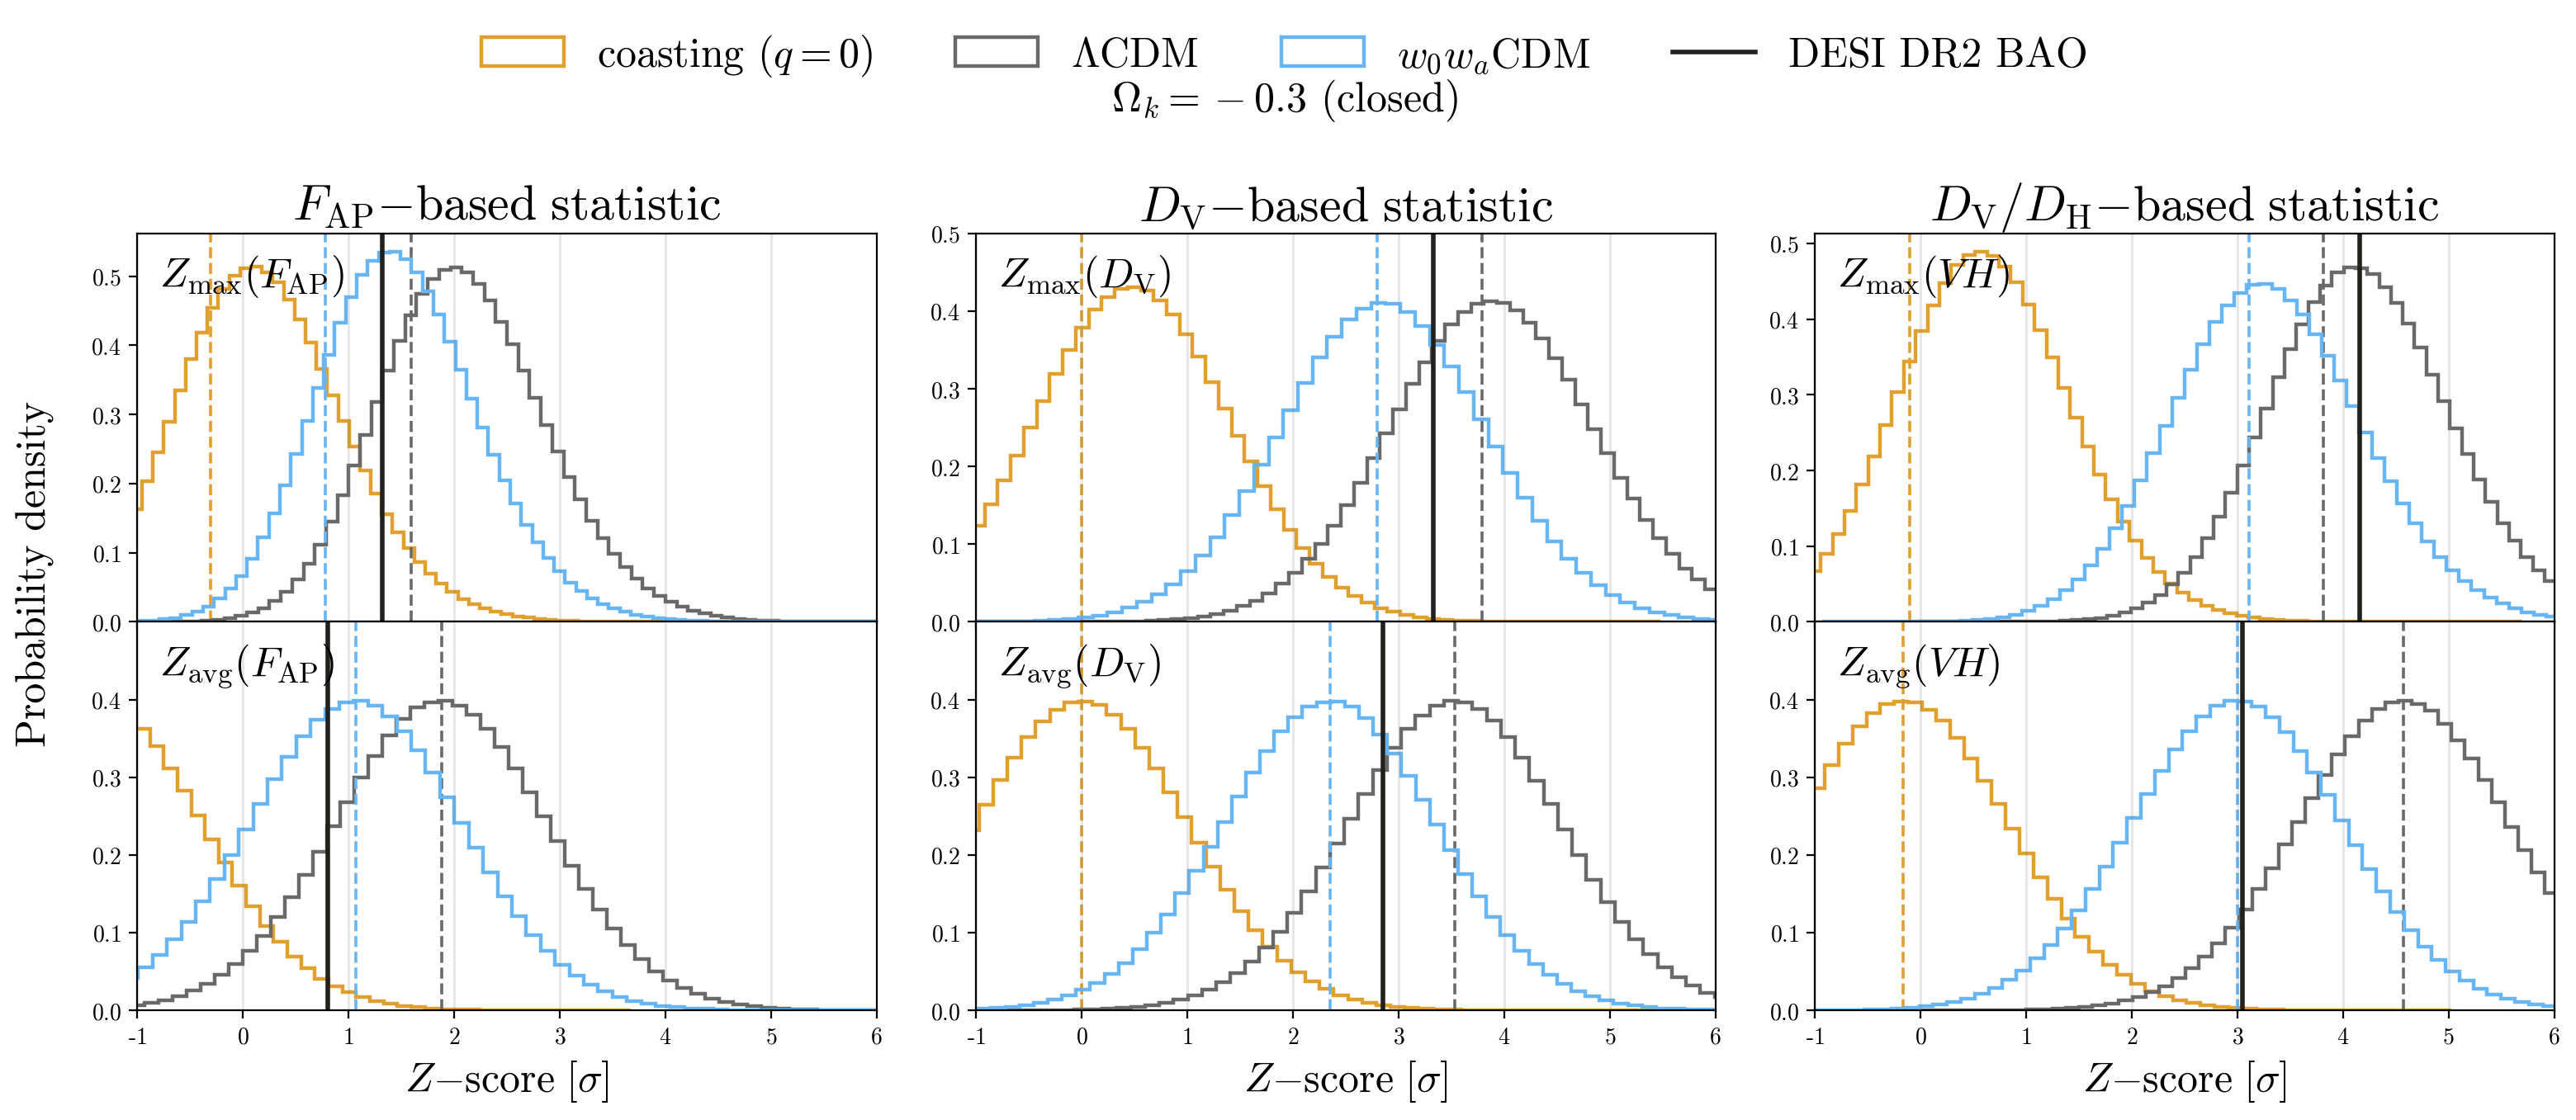

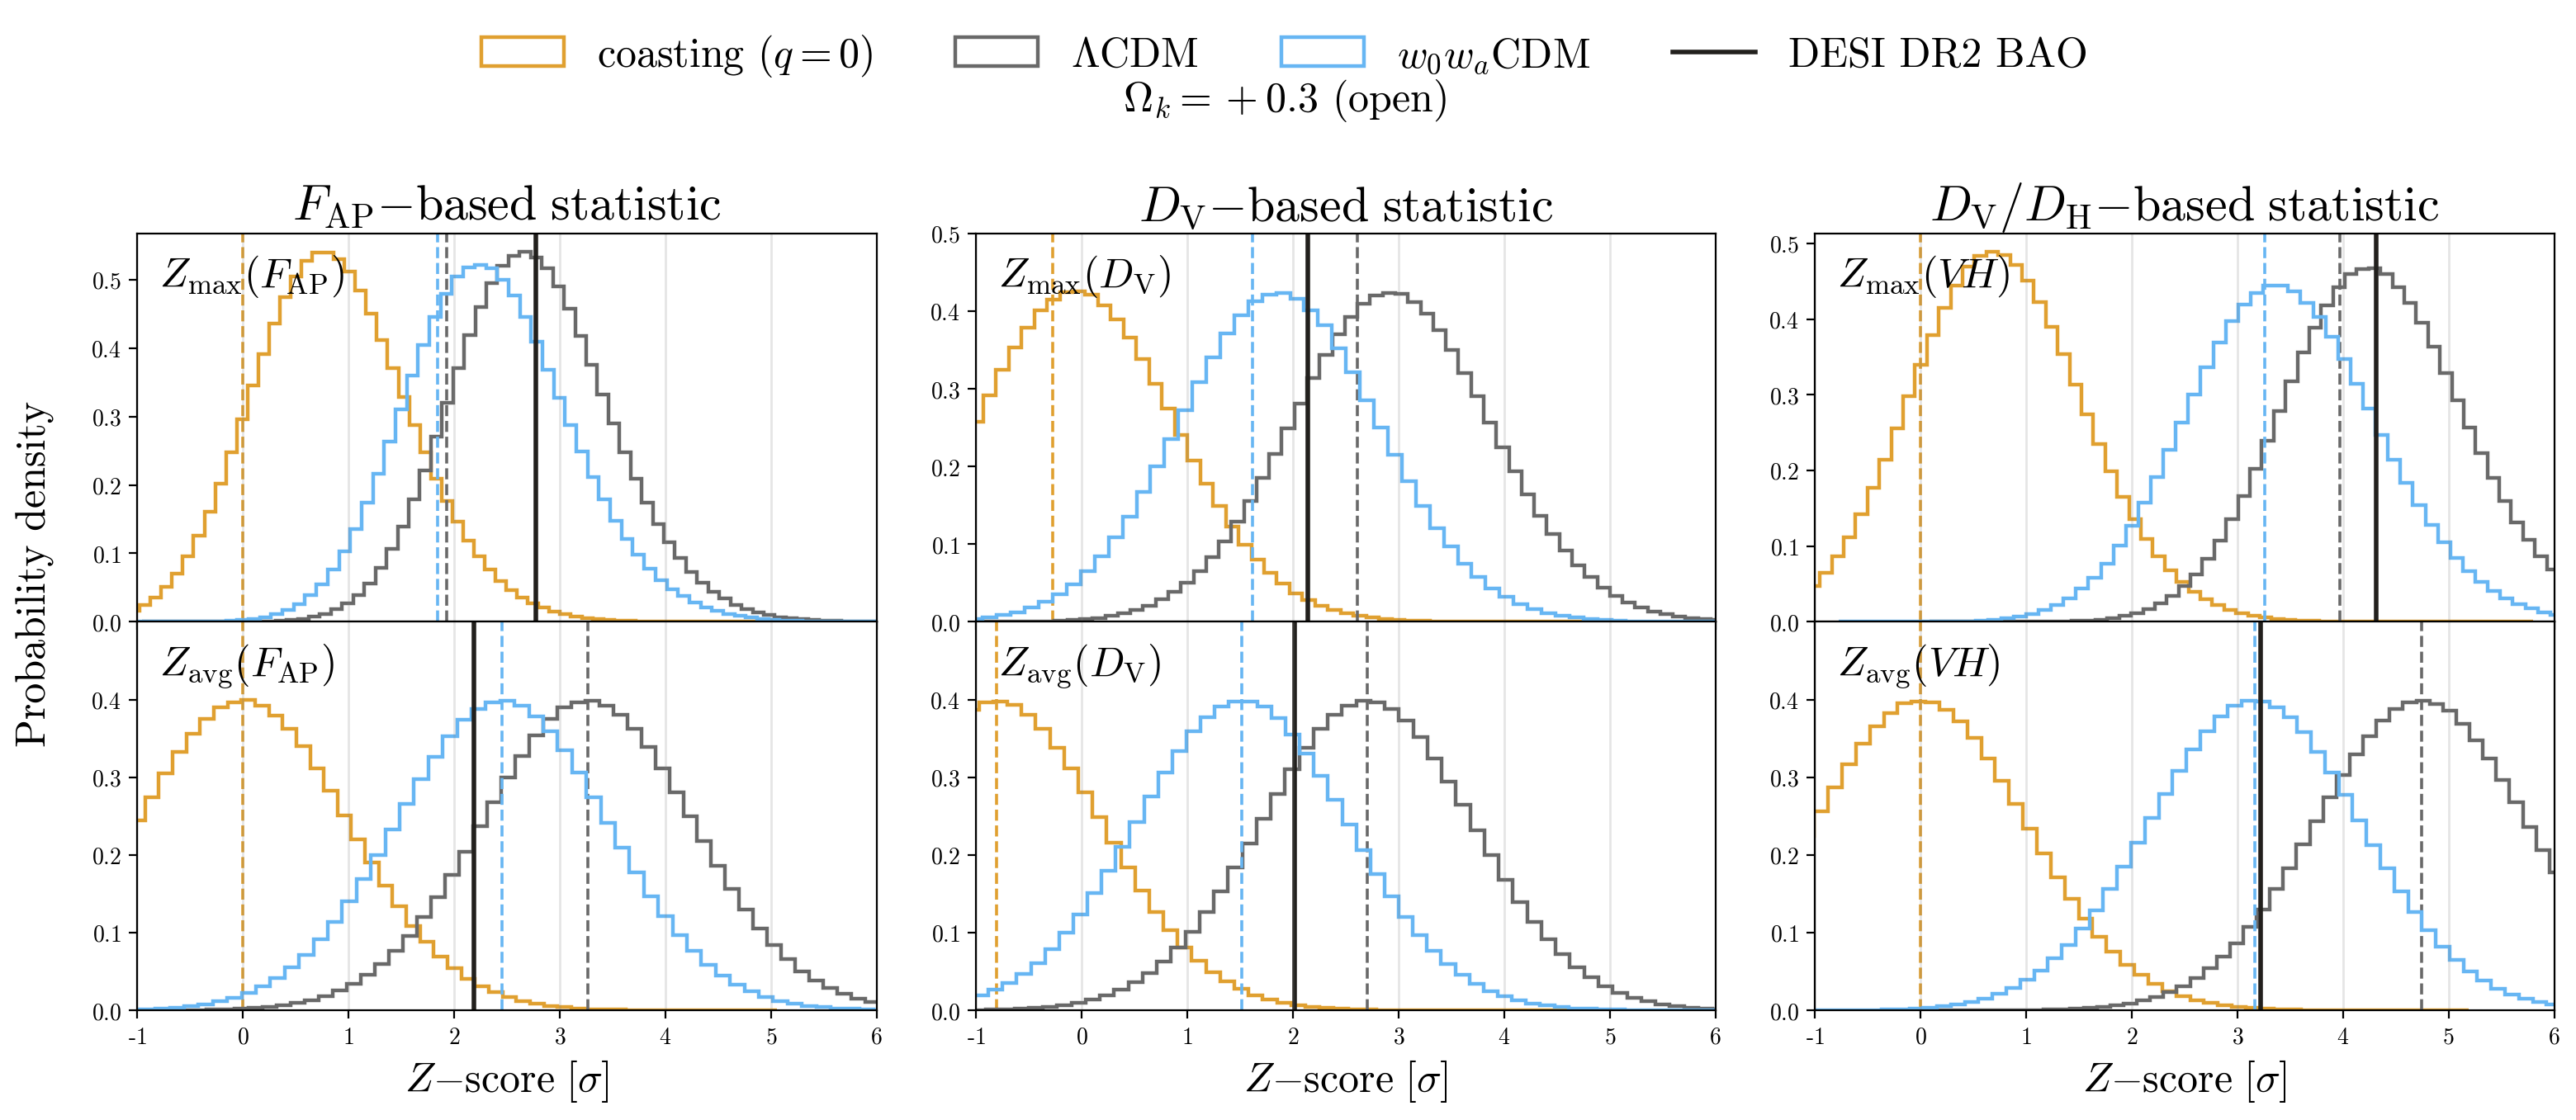

In [15]:
stat_title = {"S_F": r"$F_\mathrm{AP}\mathrm{-based\ statistic}$",
              "S_V": r"$D_\mathrm{V}\mathrm{-based\ statistic}$",
              "S_VH": r"$D_\mathrm{V}/D_\mathrm{H}\mathrm{-based\ statistic}$"}
stat_symbol = {"S_F": r"F_\mathrm{AP}", "S_V": r"D_\mathrm{V}", "S_VH": r"VH"}

for ok in OMEGA_K_FIG:
    with plt.rc_context(cm_rc):
        fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col")
        for col, stat in enumerate(("S_F", "S_V", "S_VH")):
            for row, kind in enumerate(("max", "avg")):
                ax = axes[row, col]
                for t in TRUTHS:
                    r = results[ok][stat][t]
                    ax.hist(r[f"Z{kind}_mock"], bins=80, density=True, histtype="step", color=COLORS[t], linewidth=1.6, label=LABELS[t])
                    ax.axvline(r[f"Z{kind}_true"], color=COLORS[t], ls="--", lw=1.3)
                ax.axvline(results[ok][stat][f"Z{kind}_real"], color=color_real, label=label_real, lw=2)
                ax.set_xlim(-1, 6)
                for x in range(-3, 7):
                    ax.axvline(x, color="gray", alpha=0.2, lw=1)
                ax.text(0.03, 0.95, rf"$Z_\mathrm{{{kind}}}({stat_symbol[stat]})$", transform=ax.transAxes, ha="left", va="top", fontsize=fontsize)
                if row == 0:
                    ax.set_title(stat_title[stat])
                    ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
                else:
                    ax.set_xlabel(r"$Z\mathrm{-score\ }[\sigma]$")
                    ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4])
                    ax.set_ylim(0, 0.5)
        fig.supylabel("Probability density", fontsize=fontsize, x=0.02)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.88))
        fig.subplots_adjust(hspace=0.0)
        kind_name = "closed" if ok < 0 else "open"
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False, fontsize=fontsize)
        fig.text(0.5, 0.9, rf"$\Omega_k = {ok:+.1f}$ ({kind_name})", ha="center", fontsize=fontsize)
        #plt.savefig(f"Fig2_Omk_{kind_name}.pdf", format="PDF", bbox_inches="tight")
        plt.show()